# Member 3 — Midterm: Customer Clustering & Churn-Risk Proxy

**Assumed member allocation:** The ZIP did not identify member responsibilities. This notebook covers unsupervised learning and a descriptive churn-risk proxy.

**Important limitation:** The provided RFM tables do **not** have a known actual-churn label or time-based validation split. Thus this is *not* supervised churn prediction, and the proxy must not be reported as an observed churn rate or model accuracy.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
DATA_DIR = Path('dataset') if Path('dataset/rfm_raw.csv').exists() else Path('notebooks/dataset')
OUT_DIR = DATA_DIR.resolve().parent.parent / 'outputs'
OUT_DIR.mkdir(parents=True, exist_ok=True)
rfm = pd.read_csv(DATA_DIR/'rfm_raw.csv')
assert rfm['CustomerID'].is_unique and not rfm[['Recency','Frequency','Monetary']].isna().any().any()
print(f'Loaded {len(rfm):,} customers; outputs -> {OUT_DIR.resolve()}')

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
scaled=pd.read_csv(DATA_DIR/'rfm_scaled.csv')
df=rfm.merge(scaled,on='CustomerID',suffixes=('_raw','_scaled'),validate='one_to_one')
X=df[['Recency_scaled','Frequency_scaled','Monetary_scaled']].to_numpy()
assert np.isfinite(X).all()

Loaded 5,878 customers; outputs -> /mnt/data/ecommerce_work/DataMining-Ecommerce-Analytics-main/outputs


## Choose the number of clusters
Evaluate K=2 to 7 using silhouette score on a reproducible sample of up to 2,000 customers for faster execution. `KMeans` itself is trained on all customers. Silhouette is a clustering quality metric, **not predictive accuracy**.

In [2]:
from sklearn.metrics import silhouette_score
rows=[]
for k in range(2,8):
    model=KMeans(n_clusters=k,random_state=42,n_init=10)
    labels=model.fit_predict(X)
    score=silhouette_score(X,labels,sample_size=min(2000,len(X)),random_state=42)
    rows.append({'k':k,'silhouette':score,'inertia':model.inertia_})
eval_df=pd.DataFrame(rows)
print(eval_df.round(4).to_string(index=False))
best_k=int(eval_df.loc[eval_df.silhouette.idxmax(),'k'])
print('Selected k:',best_k)
eval_df.to_csv(OUT_DIR/'member3_k_selection.csv',index=False)

 k  silhouette   inertia
 2      0.4355 8588.9853
 3      0.3461 6354.3432
 4      0.3647 4921.2333
 5      0.3465 4099.1061
 6      0.3367 3554.6963
 7      0.3067 3194.5010
Selected k: 2


In [3]:
model=KMeans(n_clusters=best_k,random_state=42,n_init=10)
df['Cluster']=model.fit_predict(X)
profiles=df.groupby('Cluster').agg(Customers=('CustomerID','size'),Median_Recency=('Recency_raw','median'),Median_Frequency=('Frequency_raw','median'),Median_Monetary=('Monetary_raw','median'),Mean_Recency=('Recency_raw','mean'),Mean_Frequency=('Frequency_raw','mean'),Mean_Monetary=('Monetary_raw','mean')).round(2)
profiles['Share_%']=(profiles['Customers']/len(df)*100).round(1)
print(profiles.to_string())
profiles.to_csv(OUT_DIR/'member3_cluster_profiles.csv')

         Customers  Median_Recency  Median_Frequency  Median_Monetary  Mean_Recency  Mean_Frequency  Mean_Monetary  Share_%
Cluster                                                                                                                    
0             3558           289.5               2.0           415.80        299.65            2.10         614.34     60.5
1             2320            24.0               8.0          2861.48         50.56           12.72        6546.97     39.5


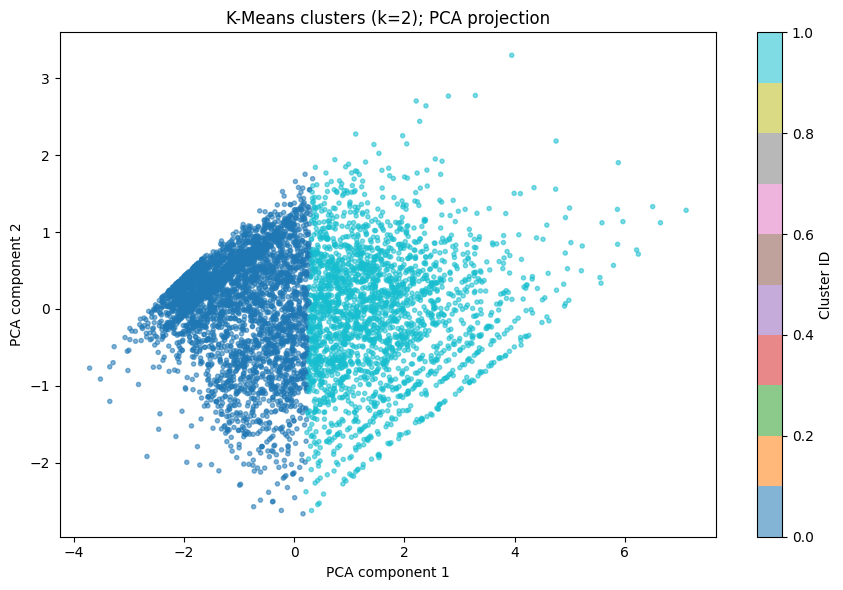

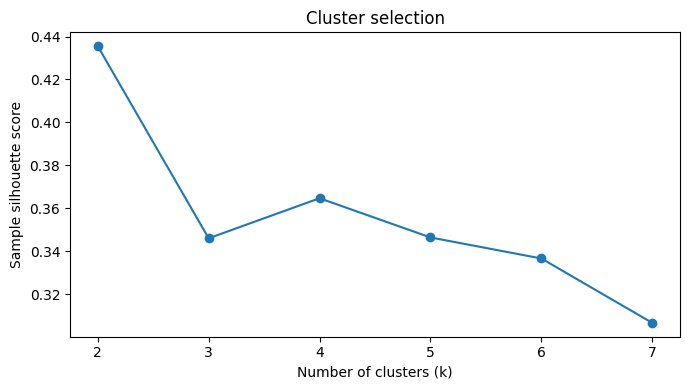

In [4]:
pca=PCA(n_components=2,random_state=42)
coords=pca.fit_transform(X)
fig,ax=plt.subplots(figsize=(9,6))
scatter=ax.scatter(coords[:,0],coords[:,1],c=df.Cluster,cmap='tab10',s=9,alpha=.55)
ax.set(xlabel='PCA component 1',ylabel='PCA component 2',title=f'K-Means clusters (k={best_k}); PCA projection')
fig.colorbar(scatter,ax=ax,label='Cluster ID');fig.tight_layout();fig.savefig(OUT_DIR/'member3_clusters_pca.png',dpi=150);plt.show()
fig,ax=plt.subplots(figsize=(7,4));ax.plot(eval_df.k,eval_df.silhouette,'o-');ax.set(xlabel='Number of clusters (k)',ylabel='Sample silhouette score',title='Cluster selection');fig.tight_layout();fig.savefig(OUT_DIR/'member3_k_selection.png',dpi=150);plt.show()

## Churn-risk *proxy*, not confirmed churn
Define an indicative inactivity flag based on recency: `Recency > 180 days` = **high inactivity risk**; `91–180` = **medium**; otherwise **low**. These are arbitrary demonstration thresholds, not calibrated probabilities. Because this dataset is a historical snapshot, there are no future outcomes here to verify who actually churned.

In [5]:
df['Inactivity_Risk']=pd.cut(df['Recency_raw'],bins=[-np.inf,90,180,np.inf],labels=['Low (<=90d)','Medium (91-180d)','High (>180d)'])
risk_summary=pd.crosstab(df.Cluster,df.Inactivity_Risk)
risk_summary['Total']=risk_summary.sum(axis=1)
print(risk_summary.to_string())
print('Overall high inactivity risk share:',round(100*(df.Inactivity_Risk=='High (>180d)').mean(),1),'%')
df[['CustomerID','Recency_raw','Frequency_raw','Monetary_raw','Cluster','Inactivity_Risk']].to_csv(OUT_DIR/'member3_customer_clusters_risk.csv',index=False)
risk_summary.to_csv(OUT_DIR/'member3_cluster_risk_summary.csv')

Inactivity_Risk  Low (<=90d)  Medium (91-180d)  High (>180d)  Total
Cluster                                                            
0                        903               388          2267   3558
1                       1986               201           133   2320
Overall high inactivity risk share: 40.8 %


## Interpretation & next steps
- Compare cluster median Recency/Frequency/Monetary to describe active, loyal, low-value and dormant groups (cluster numbering is arbitrary).
- Prioritize re-engagement for customers with high inactivity risk, especially historically high spenders.
- For **real churn prediction**, define an observation window and a subsequent outcome window from dated transaction records, then split train/test **chronologically**. Do not claim classifier accuracy from these RFM-only data.